# 56Fe(n,n'): inelastic scattering in a structural material, predicted from the other isotopes

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn.base

from xsml import data, features, splits, models, metrics, importance, libraries

In [2]:
# load the table and take neutron inelastic scattering between 0.1 and 20 MeV, unqualified cross sections
table = data.load()
inelastic = data.select(table, projectile="n", mt=4, e_min=1e5, e_max=2e7, plain=True)
inelastic = features.append(inelastic)
inelastic = inelastic.reset_index(drop=True)
inelastic["iso"] = data.isotope_id(inelastic.Z, inelastic.A)
print(len(inelastic), "points,", inelastic.iso.nunique(), "isotopes")
print(inelastic.reaction.value_counts().head(3))

35626 points, 56 isotopes
reaction
26-FE-56(N,INL)26-FE-56,,SIG      21464
11-NA-23(N,INL)11-NA-23,,SIG       3843
82-PB-207(N,INL)82-PB-207,,SIG     1738
Name: count, dtype: int64


In [3]:
# the target isotope is held out: none of its rows is used for training
Z_target = 26
A_target = 56
train_mask, test_mask = splits.leave_one_isotope_out(inelastic, Z_target, A_target)
train = inelastic[train_mask].reset_index(drop=True)
target = inelastic[test_mask].reset_index(drop=True)
splits.assert_no_leakage(train, target)
print(len(train), "training points,", len(target), "points of the target")
print(data.datasets(target)[["dataset", "author", "year", "points", "e_min_eV", "e_max_eV", "ds_flag", "ds_offset_dex"]])

14162 training points, 21464 points of the target
    dataset      author  year  ...    e_max_eV        ds_flag  ds_offset_dex
0  10529004       Perey  1971  ...   2129500.0             ok       0.116014
1  11700002  Barrows jr  1965  ...   2430000.0             ok       0.063234
2  23073004      Negret  2013  ...  17696400.0             ok       0.186117
3  23134005       Beyer  2014  ...  11348000.0             ok       0.203382
4  23313002      Dupont  1998  ...   2994600.0  normalisation      -0.304085
5  23313003      Dupont  1998  ...   2996270.0  normalisation      -0.264566
6  30656021  Shi Xiamin  1982  ...  14200000.0             ok      -0.065420
7  32201002       Korzh  1994  ...   1400000.0             ok       0.103239
8  41156006     Simakov  1992  ...  14100000.0             ok      -0.011604

[9 rows x 8 columns]


In [4]:
# all features: the energy and every nuclear property from the mass table
all_features = [
    "log10_energy", "Z", "N", "A", "atomic_mass_u", "mass_excess", "binding_energy", "B_per_A",
    "S_n", "S_p", "S_2n", "S_2p", "Q_alpha", "Q_beta_minus", "Q_ng", "Q_np", "Q_na", "Q_n2n",
    "N_minus_Z", "asymmetry", "Z_odd", "N_odd", "A_odd", "pairing",
    "Z_magic_dist", "N_magic_dist", "Z_magic", "N_magic", "P_factor", "A_third", "radius_fm",
]

model_all = models.xgboost()
model_all.fit(train[all_features], train.log10_sigma)
prediction = model_all.predict(target[all_features])
factor_all = metrics.rms_factor(target.log10_sigma, prediction)
print("all features, all rows: RMS factor on the target", round(factor_all, 2))

all features, all rows: RMS factor on the target 6.96


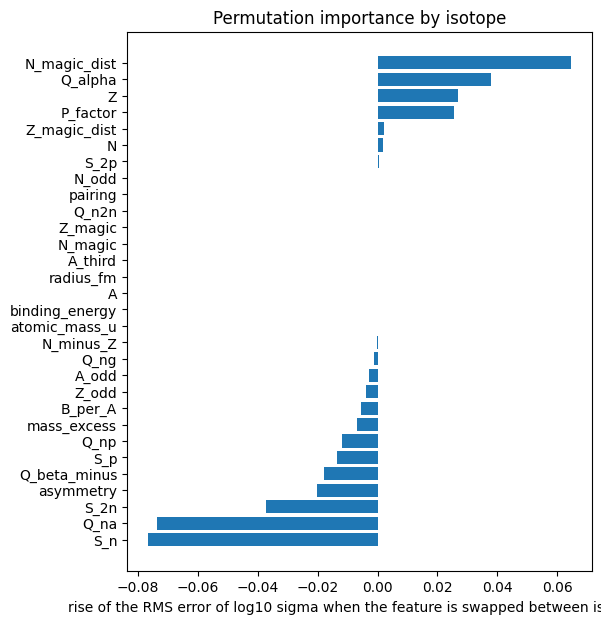

In [5]:
# naive feature importance: swap one feature between isotopes and see how much the error grows
# (measured on isotopes that the model did not train on; the energy is not an isotope property and is left out)
fold = splits.isotope_folds(train, 5)
fit_part = train[fold != 0]
check_part = train[fold == 0]
model_check = models.xgboost()
model_check.fit(fit_part[all_features], fit_part.log10_sigma)

names = []
rises = []
for name in all_features:
    if name == "log10_energy":
        continue
    result = importance.block_permutation(model_check, check_part[all_features], check_part.log10_sigma, check_part.iso, name, n_repeats=5)
    names.append(name)
    rises.append(result["mean"])
ranking = pd.Series(rises, index=names).sort_values()

plt.figure(figsize=(6, 7))
plt.barh(ranking.index, ranking.values)
plt.xlabel("rise of the RMS error of log10 sigma when the feature is swapped between isotopes")
plt.title("Permutation importance by isotope")
plt.show()

In [6]:
# training sets for a sweep: keep the datasets whose offset from the others is at most t (in dex)
# (datasets without an offset could not be compared and are kept; the other iron isotopes are always dropped; the target is never trimmed)
thresholds = [0.1, 0.2, 0.3, 0.5, None]
reference = 0.3
no_iron = train[train.Z != Z_target]
training_sets = {}
for t in thresholds:
    if t is None:
        label = "no cut"
        chosen = no_iron
    else:
        label = "t = " + str(t)
        chosen = no_iron[no_iron.ds_offset_dex.isna() | (no_iron.ds_offset_dex.abs() <= t)]
    training_sets[label] = chosen.reset_index(drop=True)
    splits.assert_no_leakage(training_sets[label], target, level="element")
    print(label, ":", len(training_sets[label]), "training points,", training_sets[label].dataset.nunique(), "datasets,", training_sets[label].iso.nunique(), "isotopes")
reference_label = "t = " + str(reference)
train_trim = training_sets[reference_label]

t = 0.1 : 12309 training points, 100 datasets, 53 isotopes
t = 0.2 : 13632 training points, 105 datasets, 53 isotopes
t = 0.3 : 13657 training points, 109 datasets, 53 isotopes
t = 0.5 : 13658 training points, 110 datasets, 53 isotopes
no cut : 13658 training points, 110 datasets, 53 isotopes


In [7]:
# three algorithms, each trained on every training set of the sweep and scored on the full target
sweep_rows = []
sweep_fitted = {}
for label in training_sets:
    rows = training_sets[label]
    row = {"threshold": label, "training points": len(rows)}
    for name in ["decision tree", "random forest", "XGBoost"]:
        if name == "decision tree":
            model = models.decision_tree()
        elif name == "random forest":
            model = models.random_forest(n_estimators=100)
        else:
            model = models.xgboost()
        model.fit(rows[all_features], rows.log10_sigma)
        sweep_fitted[(label, name)] = model
        row[name] = metrics.rms_factor(target.log10_sigma, model.predict(target[all_features]))
    sweep_rows.append(row)
sweep = pd.DataFrame(sweep_rows)
print("RMS factor on the full target,", len(target), "points")
print(sweep.round(2).to_string(index=False))

# cross-validation over isotopes on the reference training set, for the interval
cv = splits.fold_splits(train_trim, 5)
labels = ["decision tree", "random forest", "XGBoost"]
cv_scores = {}
fitted = {}
for name in labels:
    fitted[name] = sweep_fitted[(reference_label, name)]
    rmse, out_of_fold = models.cv_rmse(sklearn.base.clone(fitted[name]), train_trim[all_features], train_trim.log10_sigma, cv)
    cv_scores[name] = metrics.cluster_bootstrap(train_trim.log10_sigma, out_of_fold, train_trim.iso, n_boot=500)
    print(name, "CV RMS factor at", reference_label, ":", round(cv_scores[name]["value"], 2), "[", round(cv_scores[name]["low"], 2), ",", round(cv_scores[name]["high"], 2), "]")

RMS factor on the full target, 21464 points
threshold  training points  decision tree  random forest  XGBoost
  t = 0.1            12309           7.95           8.65     5.02
  t = 0.2            13632           7.67           8.53     4.72
  t = 0.3            13657           7.66           9.52     5.08
  t = 0.5            13658           7.66           9.04     4.66
   no cut            13658           7.66           9.04     4.66
decision tree CV RMS factor at t = 0.3 : 5.32 [ 2.82 , 8.29 ]
random forest CV RMS factor at t = 0.3 : 2.75 [ 2.22 , 3.19 ]
XGBoost CV RMS factor at t = 0.3 : 3.72 [ 2.27 , 4.85 ]


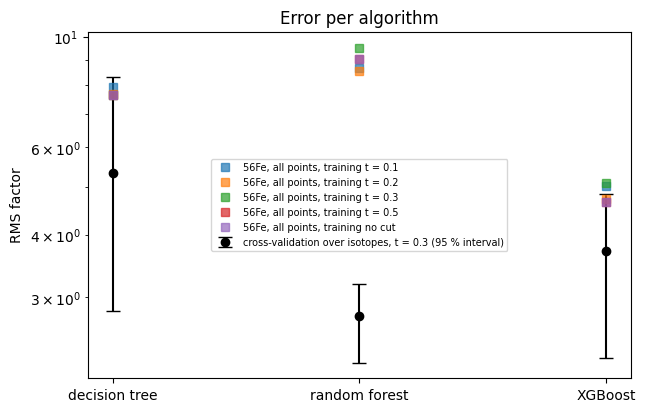

In [8]:
# error per algorithm: the interval over isotopes, and the full target for every threshold
values = np.array([cv_scores[name]["value"] for name in labels])
lows = np.array([cv_scores[name]["low"] for name in labels])
highs = np.array([cv_scores[name]["high"] for name in labels])

plt.figure(figsize=(7, 4.5))
plt.errorbar(labels, values, yerr=[values - lows, highs - values], fmt="o", color="k", capsize=5, label="cross-validation over isotopes, " + reference_label + " (95 % interval)")
for label in training_sets:
    on_target = sweep[sweep.threshold == label][labels].to_numpy()[0]
    plt.plot(labels, on_target, "s", alpha=0.7, label="56Fe, all points, training " + label)
plt.yscale("log")
plt.ylabel("RMS factor")
plt.title("Error per algorithm")
plt.legend(fontsize=7)
plt.show()

In [9]:
# RMS factor on the target, dataset by dataset, without a cut and at the reference threshold
target_dataset = target.dataset.astype(str)
per_dataset = data.datasets(target)[["dataset", "author", "year", "points", "ds_flag", "ds_offset_dex"]]
per_dataset["dataset"] = per_dataset.dataset.astype(str)
per_dataset = per_dataset.set_index("dataset")
for name in labels:
    for label in ["no cut", reference_label]:
        prediction = sweep_fitted[(label, name)].predict(target[all_features])
        per_dataset[name + ", " + label] = metrics.per_group(target.log10_sigma, prediction, target_dataset)
print(per_dataset.round(2).to_string())

              author  year  points        ds_flag  ds_offset_dex  decision tree, no cut  decision tree, t = 0.3  random forest, no cut  random forest, t = 0.3  XGBoost, no cut  XGBoost, t = 0.3
dataset                                                                                                                                                                                          
10529004       Perey  1971     585             ok           0.12                   3.39                    3.39                   3.84                    3.86             3.10              3.08
11700002  Barrows jr  1965       3             ok           0.06                   1.21                    1.21                   1.17                    1.17             1.15              1.15
23073004      Negret  2013    1024             ok           0.19                   1.82                    1.83                   1.86                    1.85             1.82              1.76
23134005       Beyer  2014    

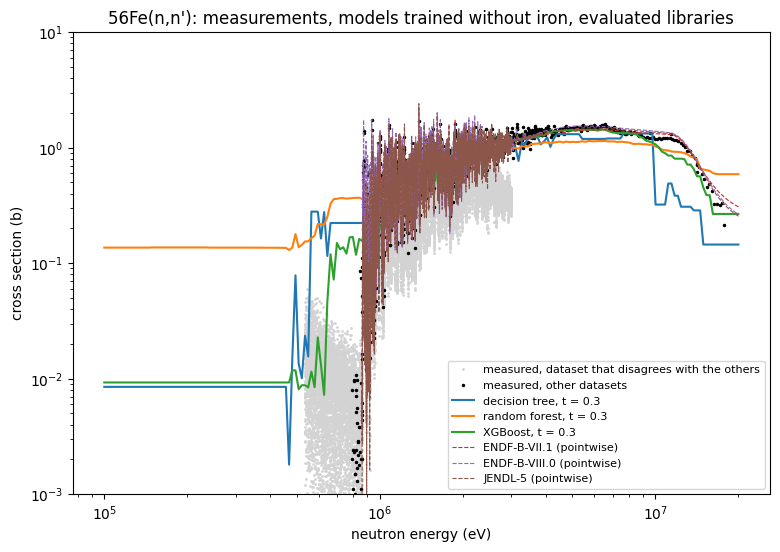

In [10]:
# the data of 56Fe, the three model curves and the evaluated libraries
# (grey: datasets of the target that disagree with the others; they are not removed and are scored like the rest)
grid = pd.DataFrame({"projectile": "n", "Z": Z_target, "A": A_target, "MT": 4, "reaction": target.reaction.iloc[0],
                     "energy_eV": np.logspace(5, np.log10(2e7), 200), "sigma_b": 1.0})
grid = features.append(grid)
flagged = ["normalisation", "shape", "normalisation+shape"]
target_flagged = target[target.ds_flag.isin(flagged)]
target_other = target[~target.ds_flag.isin(flagged)]

plt.figure(figsize=(9, 6))
plt.loglog(target_flagged.energy_eV, target_flagged.sigma_b, ".", color="lightgrey", markersize=2, label="measured, dataset that disagrees with the others")
plt.loglog(target_other.energy_eV, target_other.sigma_b, "k.", markersize=3, label="measured, other datasets")
for name in fitted:
    plt.loglog(grid.energy_eV, 10 ** fitted[name].predict(grid[all_features]), label=name + ", " + reference_label)
for library in ["ENDF-B-VII.1", "ENDF-B-VIII.0", "JENDL-5"]:
    curve = libraries.curve("Fe-56", 4, library)
    curve = curve[curve.sigma_b > 0]
    plt.loglog(curve.energy_eV, curve.sigma_b, linewidth=0.8, linestyle="--", label=library + " (pointwise)")
plt.ylim(1e-3, 10)
plt.xlabel("neutron energy (eV)")
plt.ylabel("cross section (b)")
plt.title("56Fe(n,n'): measurements, models trained without iron, evaluated libraries")
plt.legend(fontsize=8)
plt.show()

In [11]:
# log every score
log = "score_log_examples.csv"
for name in labels:
    metrics.log_score(log, model=name, features=all_features, split="5 isotope folds, training: |ds_offset_dex| <= 0.3, no Fe", metric="rms_factor",
                      value=cv_scores[name]["value"], ci_low=cv_scores[name]["low"], ci_high=cv_scores[name]["high"],
                      n_groups=cv_scores[name]["n_groups"], n_points=cv_scores[name]["n_points"])
    for label in training_sets:
        value = sweep[sweep.threshold == label][name].iloc[0]
        metrics.log_score(log, model=name, features=all_features, split="56Fe held out, all target points, training: offset cut " + label + ", no Fe", metric="rms_factor",
                          value=value, n_groups=1, n_points=len(target), notes="no interval: one isotope")
print(pd.read_csv(log).tail(18)[["model", "split", "value", "ci_low", "ci_high", "n_points"]].to_string())

            model                                                                  split     value    ci_low   ci_high  n_points
0   decision tree               5 isotope folds, training: |ds_offset_dex| <= 0.3, no Fe  5.321935  2.819660  8.292526     13657
1   decision tree  56Fe held out, all target points, training: offset cut t = 0.1, no Fe  7.950130       NaN       NaN     21464
2   decision tree  56Fe held out, all target points, training: offset cut t = 0.2, no Fe  7.670680       NaN       NaN     21464
3   decision tree  56Fe held out, all target points, training: offset cut t = 0.3, no Fe  7.657465       NaN       NaN     21464
4   decision tree  56Fe held out, all target points, training: offset cut t = 0.5, no Fe  7.656668       NaN       NaN     21464
5   decision tree   56Fe held out, all target points, training: offset cut no cut, no Fe  7.656668       NaN       NaN     21464
6   random forest               5 isotope folds, training: |ds_offset_dex| <= 0.3, no Fe  2.74548